# Global Graph:

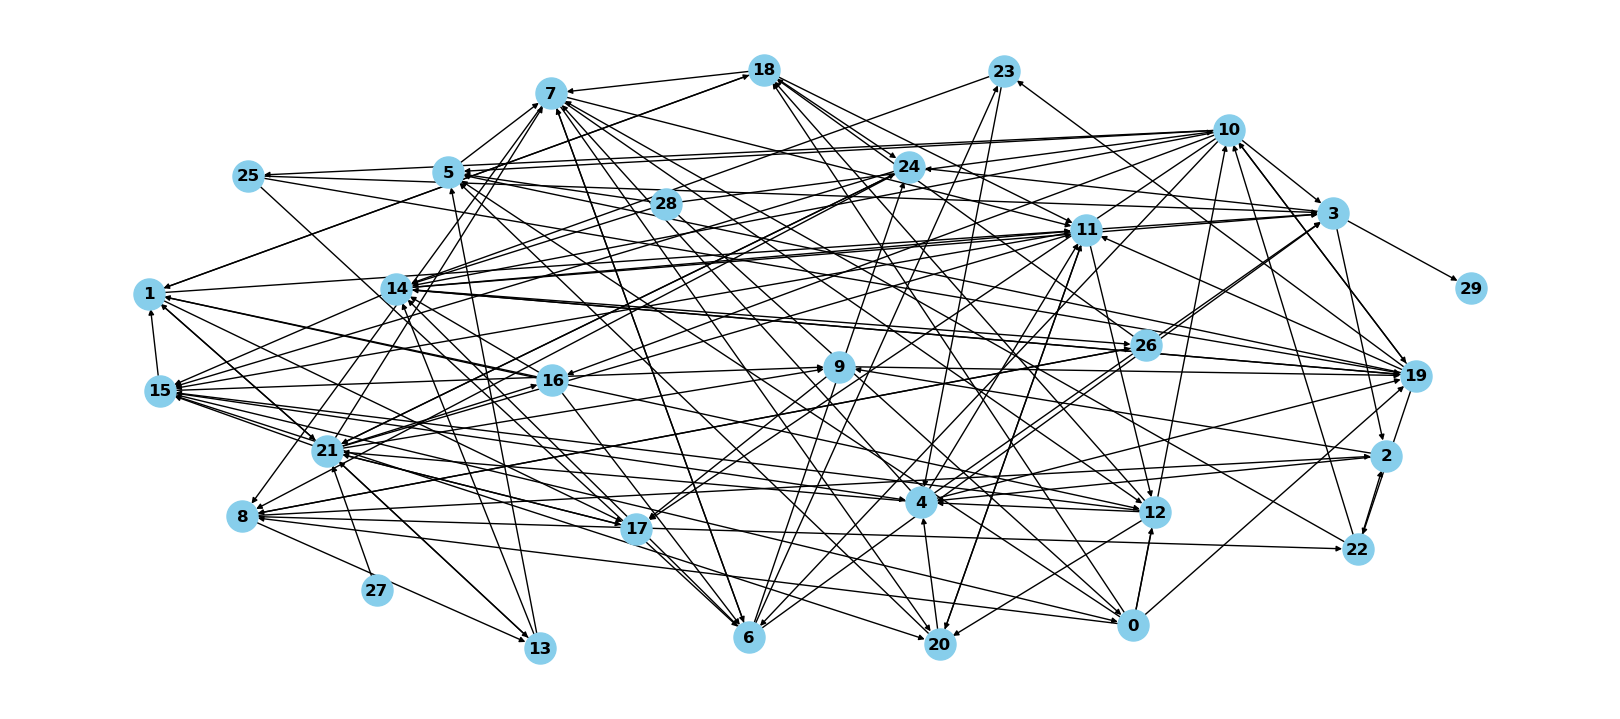

In [1]:
from const import sim_kwargs, SOURCE_SINK_PAIRS
from toy_models.create import ToyBarabasi
import matplotlib.pyplot as plt
import networkx as nx

prb = ToyBarabasi(cutoff=0.8)
subgraphs = prb.subgraphs

kwargs = dict(
    pos=nx.arf_layout(prb.G, seed=123), 
    arrowsize=8, node_color='skyblue', 
    with_labels=True, font_weight='bold', node_size=500
    )

plt.figure(figsize=(16, 7))
nx.draw(prb.G, **kwargs)
plt.show()

# Subgraphs:

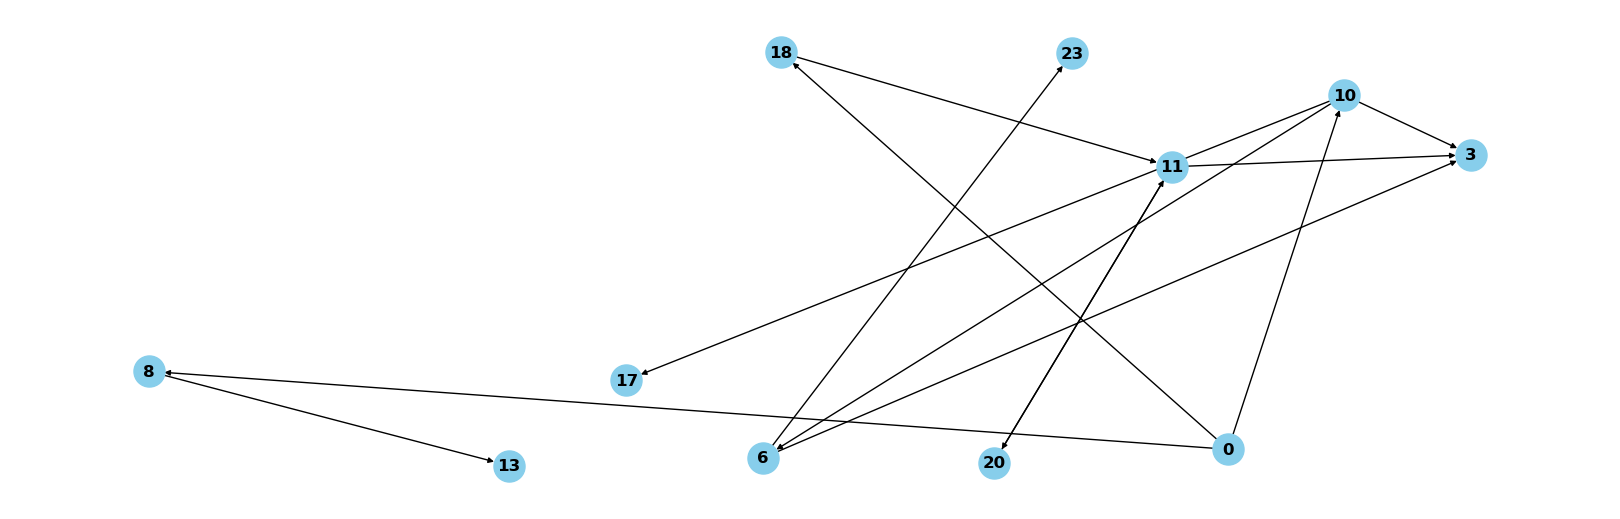

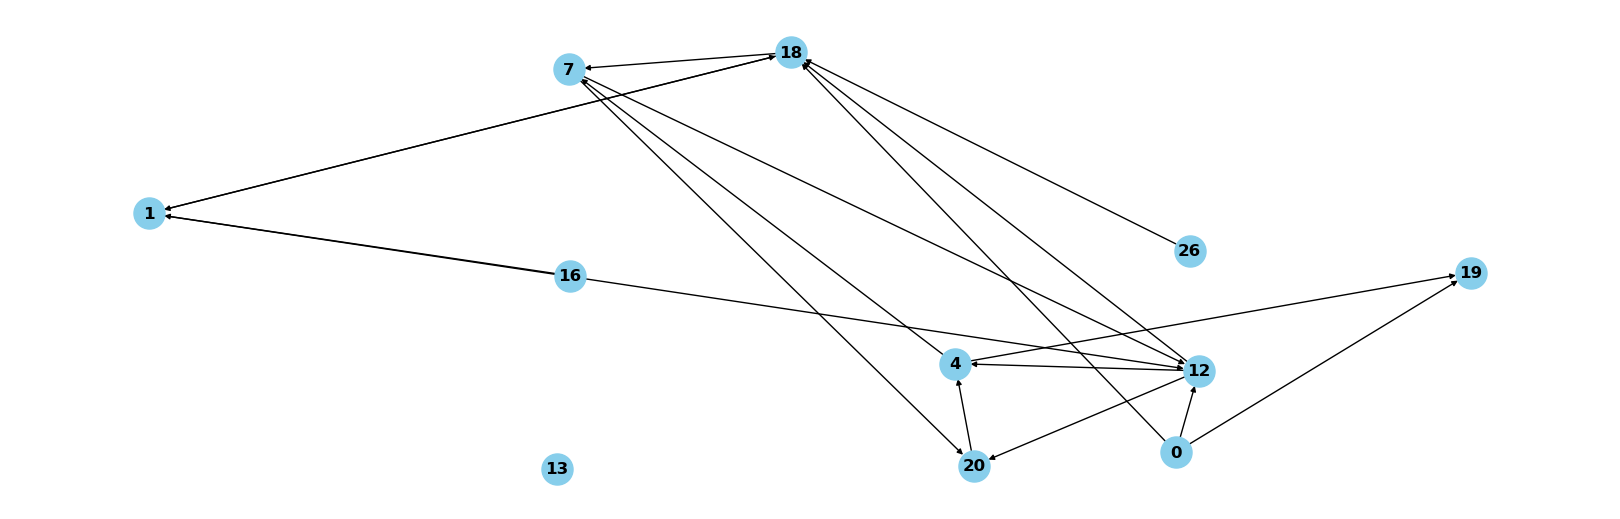

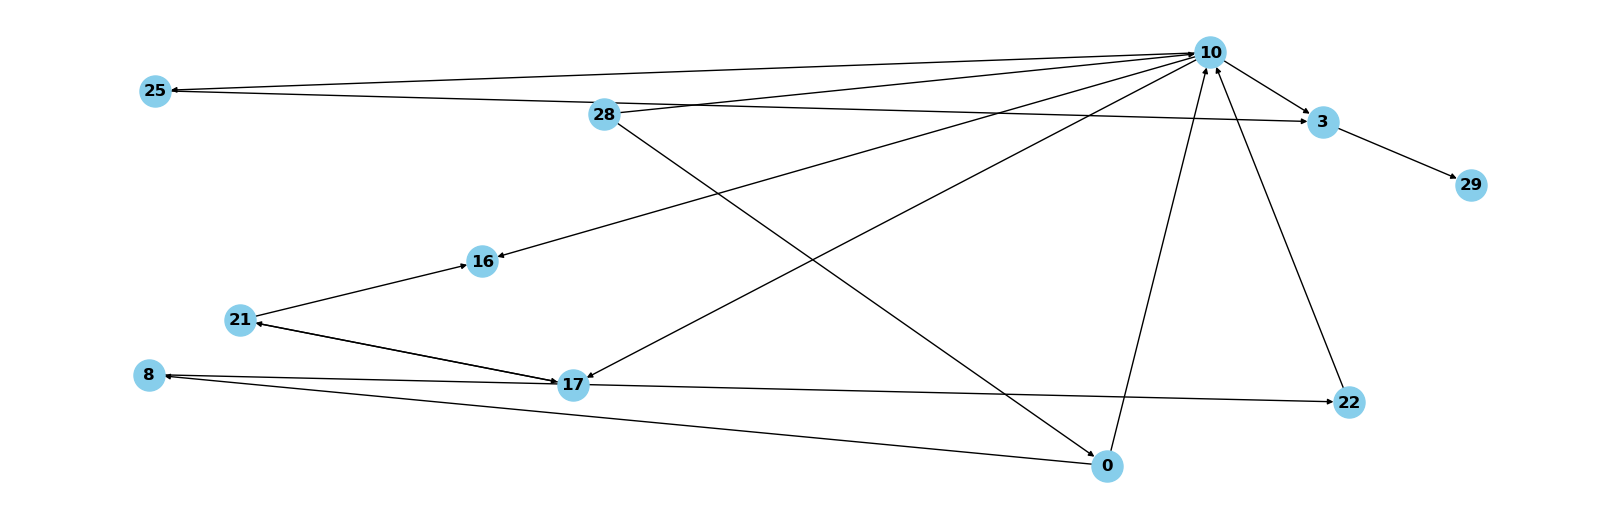

In [2]:
for g in prb.subgraphs:
    plt.figure(figsize=(16, 5))
    nx.draw(g, **kwargs)
    plt.show()

# Simulation Analysis:

## Problem Features:
- Subgraphs
- Specific Source/Sink Nodes
- See const.py for all features of the simulation and analysis 

In [ ]:
from standard_assessment import Sim 
sim = Sim(prb.G, prb.subgraphs, **sim_kwargs)
reachability, distance = sim.run_threshold_simulation(SOURCE_SINK_PAIRS)
reachability_rate = reachability.mean(axis=2)

mean_distance = sim.calculate_mean_distance(distance)
print(reachability_rate[0:10, 0:5])
print(mean_distance.shape)

Dijkstra Simulation:   0%|          | 0/210000 [00:00<?, ?run/s]

IndexError: too many indices for array: array is 2-dimensional, but 3 were indexed

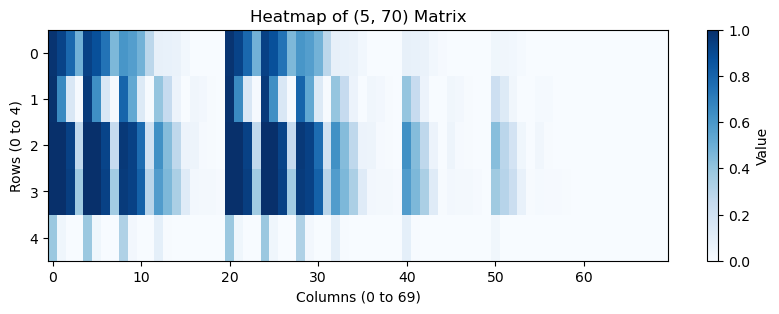

In [13]:
plt.figure(figsize=(10, 3))
# aspect='auto' stretches the 5 rows to fit nicely
plt.imshow(reachability_rate, aspect="auto", cmap="Blues")
plt.colorbar(label="Value")
plt.xlabel("Columns (0 to 69)")
plt.ylabel("Rows (0 to 4)")
plt.title("Heatmap of (5, 70) Matrix")
plt.show()